# 03. 무엇이 혼잡도를 결정하는가 (회귀 분석)

**질문**
1. 환승역은 정말 더 붐비는가? 시각·노선·방향을 통제해도 그런가?
2. 혼잡도의 차이를 시각, 노선, 방향, 역이 각각 얼마나 설명하는가?

**데이터**: 평일, 역·방향·30분 슬롯 단위(미운행 제외).
**환승역 정의**: 서울시 역사마스터(수도권 전체 노선)로 판별한다(`src/subway/transfer.py`).
**표준오차**: 같은 역의 관측치는 서로 비슷하므로 **역 단위 군집 표준오차**(cluster-robust SE)를 쓴다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from subway.load import load_congestion
from subway.clean import clean_congestion
from subway.transfer import load_station_master, transfer_table, far_same_name_pairs

sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.precision", 3)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, FIG = ROOT / "data" / "raw", ROOT / "reports" / "figures"

df = clean_congestion(load_congestion(RAW / "서울교통공사_지하철혼잡도정보_20260930.csv"))
master = load_station_master(RAW / "서울시 역사마스터 정보.csv")
transfers = transfer_table(master)

## 1. 환승역 판별

In [2]:
stations = df[["line", "station"]].drop_duplicates()
lines_in_data = stations.groupby("station").line.nunique()
stations["환승(1~8호선 기준)"] = stations.station.map(lines_in_data > 1).astype(int)
stations = stations.merge(transfers, on=["line", "station"], how="left")
assert stations.is_transfer.notna().all(), "역사마스터와 매칭되지 않는 역이 있음"

print(f"1~8호선 (노선, 역) {len(stations)}개")
print(f"  1~8호선 기준 환승역: {stations['환승(1~8호선 기준)'].sum()}개")
print(f"  전체 노선 기준 환승역: {stations.is_transfer.sum()}개")
newly = stations[(stations.is_transfer == 1) & (stations["환승(1~8호선 기준)"] == 0)]
print(f"  새로 환승역이 된 역: {len(newly)}개")
newly[["line", "station", "other_lines"]].sort_values(["line", "station"]).reset_index(drop=True)

1~8호선 (노선, 역) 277개
  1~8호선 기준 환승역: 70개
  전체 노선 기준 환승역: 109개
  새로 환승역이 된 역: 39개


,line,station,other_lines
0,1,청량리,"경의중앙선, 수인분당선"
1,2,강남,신분당선
2,2,당산,9호선
3,2,삼성,수도권 광역급행철도
4,2,선릉,수인분당선
5,2,신도림,1호선
6,2,신림,신림선
7,2,종합운동장,9호선
8,2,홍대입구,"경의중앙선, 공항철도1호선"
9,3,도곡,수인분당선


판별 규칙: **역명(별칭 포함)이 같고 600m 이내**이면 같은 환승역으로 본다.
- 이름이 달라도 같은 역: 7호선 이수 = 4호선 총신대입구, GTX-A 서울 = 서울역
- 이름이 같아도 다른 역: 아래 표처럼 600m보다 멀면 환승역으로 묶지 않는다.
- 역사마스터에 빠진 항목(2호선 까치산, 1호선 창동, 수인분당선 왕십리·청량리, 경춘선 상봉)은 `MASTER_SUPPLEMENT`로 보충했다.

In [3]:
far_same_name_pairs(master).round(2)

,station,service_line_a,service_line_b,km
988,신촌,2호선,경의중앙선,0.72
769,운정,경의중앙선,수도권 광역급행철도,3.58
521,양평,5호선,경의중앙선,53.55


## 2. 모델을 하나씩 키워 보기

In [4]:
wk = df[df.day_type == "평일"].dropna(subset=["congestion"]).merge(
    stations[["line", "station", "is_transfer", "n_lines", "환승(1~8호선 기준)"]], on=["line", "station"])
wk = wk.rename(columns={"환승(1~8호선 기준)": "transfer_core"})
wk["slot"] = wk.hour.map(lambda h: f"{h:05.2f}")
wk["dirn"] = wk.direction.replace({"내선": "상선", "외선": "하선"})  # 2호선은 노선 안에서만 비교되므로 이름만 맞춘다
wk["series"] = wk.line.astype(str) + "_" + wk.station_code.astype(str) + "_" + wk.direction
groups = pd.factorize(wk.line.astype(str) + wk.station)[0]
print(f"관측치 {len(wk):,}개, 역 {groups.max() + 1}개")

def fit(formula, data=wk, g=groups):
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": g})

models = {
    "M0 환승(1~8호선 기준)": "congestion ~ transfer_core",
    "M1 환승(전체 노선)": "congestion ~ is_transfer",
    "M2 + 시각": "congestion ~ is_transfer + C(slot)",
    "M3 + 노선": "congestion ~ is_transfer + C(slot) + C(line)",
    "M4 + 노선×시각": "congestion ~ is_transfer + C(line) * C(slot)",
    "M5 + 노선×방향×시각": "congestion ~ is_transfer + C(line):C(dirn):C(slot)",
}
rows, fits = [], {}
for name, f in models.items():
    r = fits[name] = fit(f)
    var = "transfer_core" if "transfer_core" in f else "is_transfer"
    lo, hi = r.conf_int().loc[var]
    rows.append({"모델": name, "R²": r.rsquared, "조정 R²": r.rsquared_adj, "변수 수": len(r.params),
                 "환승 계수(%p)": r.params[var], "95% CI 하한": lo, "95% CI 상한": hi, "p": r.pvalues[var]})
table = pd.DataFrame(rows).set_index("모델")
table.round(3)

관측치 21,134개, 역 277개


,R²,조정 R²,변수 수,환승 계수(%p),95% CI 하한,95% CI 상한,p
모델,,,,,,,
M0 환승(1~8호선 기준),0.006,0.006,2,3.988,1.111,6.866,0.007
M1 환승(전체 노선),0.005,0.005,2,3.240,0.491,5.988,0.021
M2 + 시각,0.291,0.290,40,3.246,0.483,6.010,0.021
M3 + 노선,0.323,0.322,47,3.082,0.450,5.714,0.022
M4 + 노선×시각,0.344,0.334,313,3.082,0.433,5.731,0.023
M5 + 노선×방향×시각,0.385,0.367,625,3.069,0.402,5.737,0.024


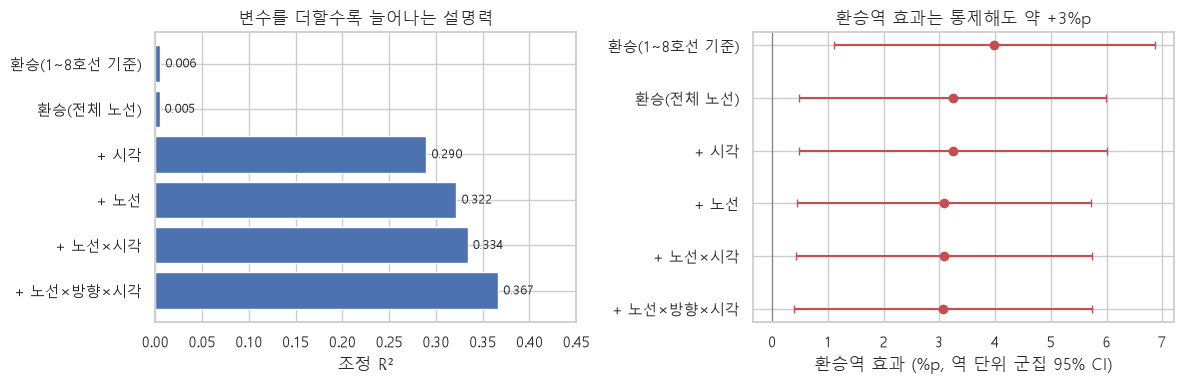

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = [n.split(" ", 1)[1] for n in table.index]
axes[0].barh(labels, table["조정 R²"], color="#4c72b0"); axes[0].invert_yaxis()
for i, v in enumerate(table["조정 R²"]): axes[0].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
axes[0].set(xlabel="조정 R²", title="변수를 더할수록 늘어나는 설명력", xlim=(0, 0.45))

axes[1].errorbar(table["환승 계수(%p)"], range(len(table)),
                 xerr=[table["환승 계수(%p)"] - table["95% CI 하한"], table["95% CI 상한"] - table["환승 계수(%p)"]],
                 fmt="o", color="#c44e52", capsize=3)
axes[1].axvline(0, color="gray", lw=0.8); axes[1].set_yticks(range(len(table))); axes[1].set_yticklabels(labels); axes[1].invert_yaxis()
axes[1].set(xlabel="환승역 효과 (%p, 역 단위 군집 95% CI)", title="환승역 효과는 통제해도 약 +3%p")
plt.tight_layout(); plt.savefig(FIG / "06_regression_models.png", dpi=150); plt.show()

- **환승 여부 하나로는 혼잡도 차이의 0.5%만 설명한다**(M1 R² = 0.005).
- **시각을 넣으면 29%로 뛴다**(M2). 혼잡도를 가장 크게 좌우하는 것은 '언제 타느냐'다.
- 노선, 노선×시각, 노선×방향×시각을 더해도 조정 R²는 0.37까지만 오른다.
- 환승역 효과는 모든 모델에서 **약 +3%p**(95% CI 대략 0.4~5.7%p)로 거의 변하지 않는다. 통계적으로는 유의하지만(p ≈ 0.02), 피크와 비피크의 차이(수십 %p)에 비하면 작다.
- 환승역 판별 기준을 1~8호선 내부에서 전체 노선으로 바꿔도 계수는 4.0 → 3.2%p로 조금 줄었을 뿐이다. **판별 기준이 결론을 바꾸지는 않았다.** 다만 1~8호선 기준으로는 신도림·강남·홍대입구 같은 역이 일반역으로 들어가 있었으므로, 앞으로의 분석과 앱에는 전체 노선 기준을 쓴다.

## 3. 환승 노선 수에 따라 달라지나

In [6]:
r = fit("congestion ~ C(n_lines) + C(line):C(dirn):C(slot)")
n_station = stations.groupby("n_lines").size()
eff = pd.DataFrame({"계수(%p, 비환승 대비)": r.params.filter(like="n_lines"), "p": r.pvalues.filter(like="n_lines")})
eff.index = [int(i.split("T.")[1].rstrip("]")) for i in eff.index]
eff["(노선, 역) 수"] = n_station.reindex(eff.index)
eff.index.name = "만나는 노선 수"
eff.round(3)

,"계수(%p, 비환승 대비)",p,"(노선, 역) 수"
만나는 노선 수,,,
2,3.314,0.023,85
3,2.049,0.395,17
4,6.885,0.000,4
5,-5.374,0.443,3


노선 수가 많을수록 더 붐비는 단조로운 관계는 보이지 않는다. 4개 노선이 만나는 역(왕십리·공덕)만 +7%p로 뚜렷하고, 5개 노선(서울역·김포공항)은 오히려 낮다.
역 수가 몇 개 되지 않아 개별 역의 특성이 그대로 드러난 결과로 보는 것이 맞다.

## 4. 나머지는 무엇이 설명하나

In [7]:
import warnings
with warnings.catch_warnings():
    # 역·방향 고정효과와 노선×방향 항이 겹쳐 행렬이 특이해진다. 계수는 유일하지 않지만 R²(적합값)는 영향받지 않는다.
    warnings.simplefilter("ignore")
    r_series = smf.ols("congestion ~ C(series) + C(line):C(dirn):C(slot)", wk).fit()
total = wk.congestion.var()
series_mean = wk.groupby("series").congestion.transform("mean")
decomp = pd.Series({
    "역·방향 평균 차이 (어느 역·방향이냐)": series_mean.var() / total,
    "같은 역·방향 안의 시간 변화": (wk.congestion - series_mean).var() / total,
})
print(decomp.round(3).to_string())
print(f"\n역·방향 고정효과 + 노선×방향×시각 모델 R² = {r_series.rsquared:.3f}")

역·방향 평균 차이 (어느 역·방향이냐)    0.282
같은 역·방향 안의 시간 변화          0.718

역·방향 고정효과 + 노선×방향×시각 모델 R² = 0.633


- 전체 변동의 약 **28%는 '어느 역·방향이냐'**, 나머지 **72%는 같은 역·방향 안에서 시간에 따라 변하는 부분**이다.
- 역·방향마다 고정효과를 두고 노선×방향×시각 패턴을 더하면 R²는 **0.63**까지 오른다. 그래도 37%가 남는 이유는, 같은 노선·같은 방향 안에서도 **역마다 피크 시각과 피크 높이가 다르기 때문**이다. 이 모델은 '역마다 평균 수준만 다르고 하루 곡선 모양은 노선·방향별로 같다'고 가정하는데, 실제로는 그렇지 않다.
- 즉 혼잡도는 "환승역인가, 몇 호선인가" 같은 역의 속성보다 **그 역·방향의 하루 곡선**으로 이해해야 한다. 다음 단계에서 역·방향의 하루 곡선 자체로 군집화하는 이유다.

## 정리

| 질문 | 결과 |
|---|---|
| 환승역이 더 붐비나 | 그렇다. 시각·노선·방향을 통제해도 **약 +3%p**(95% CI 0.4~5.7, 역 단위 군집 SE). 하지만 시각 효과에 비하면 작다 |
| 무엇이 가장 많이 설명하나 | **시각**(R² 0.005 → 0.29). 노선·방향을 더해도 조정 R² 0.37 |
| 나머지는 | 역·방향마다 다른 하루 곡선. 역 속성보다 곡선 모양이 중요하다 |
| 환승역 판별 기준의 영향 | 1~8호선 기준 → 전체 노선 기준으로 바꿔도 계수 4.0 → 3.2%p. 결론은 같다 |

**한계**
- 역의 위치(도심과의 거리), 주변 상권·주거지, 열차 배차 간격 같은 변수는 넣지 않았다.
- 환승 판별은 역명·좌표 기준이라, 실제 환승 통로 길이나 환승객 수는 반영하지 못한다.
- 역사마스터에는 아직 개통하지 않은 역(예: GTX-A 삼성)이 들어 있을 수 있다. 이런 역이 환승역으로 잡혀도 환승 효과 추정에 주는 영향은 1~2개 역 수준이다.

다음 노트북: `04_clustering.ipynb`에서 역·방향의 하루 혼잡도 곡선으로 군집화한다.